### Étape 1 : Chargement et découverte des données

In [102]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


df=pd.read_csv("PJME_hourly.csv")
df.head() 

,Datetime,PJME_MW
0,2002-12-31 01:00:00,26498.0
1,2002-12-31 02:00:00,25147.0
2,2002-12-31 03:00:00,24574.0
3,2002-12-31 04:00:00,24393.0
4,2002-12-31 05:00:00,24860.0


In [103]:
print(df.dtypes)  #Datetime is  str 

Datetime        str
PJME_MW     float64
dtype: object


In [104]:
df["Datetime"]=pd.to_datetime(df["Datetime"])
print(df.dtypes)

Datetime    datetime64[us]
PJME_MW            float64
dtype: object


In [105]:
# Explorer la structure, les types de données et les statistiques descriptives

print(df.columns)
print(df.shape)
df.describe()

Index(['Datetime', 'PJME_MW'], dtype='str')
(145366, 2)


,Datetime,PJME_MW
count,145366,145366.000000
mean,2010-04-18 03:25:25.999202,32080.222831
min,2002-01-01 01:00:00,14544.000000
25%,2006-02-23 14:15:00,27573.000000
50%,2010-04-18 04:30:00,31421.000000
75%,2014-06-10 18:45:00,35650.000000
max,2018-08-03 00:00:00,62009.000000
std,NaN,6464.012166


In [106]:
#Extrait valeur manquante
missing_values = df.isnull().sum()
print("Valeurs manquantes par colonne :\n", missing_values)

Valeurs manquantes par colonne :
 Datetime    0
PJME_MW     0
dtype: int64


In [107]:
#Examiner la répartition tomporelle 
df['Year'] = df['Datetime'].dt.year
df['Month'] = df['Datetime'].dt.month
df['Day'] = df['Datetime'].dt.day
df['Hour'] = df['Datetime'].dt.hour

print(df[['Year', 'Month', 'Day', 'Hour']].head())

   Year  Month  Day  Hour
0  2002     12   31     1
1  2002     12   31     2
2  2002     12   31     3
3  2002     12   31     4
4  2002     12   31     5


In [108]:
#Affiche observation par mois 
df["Month"].value_counts().sort_index()

Month
1     12647
2     11520
3     12636
4     12235
5     12648
6     12240
7     12648
8     11953
9     11520
10    11899
11    11517
12    11903
Name: count, dtype: int64

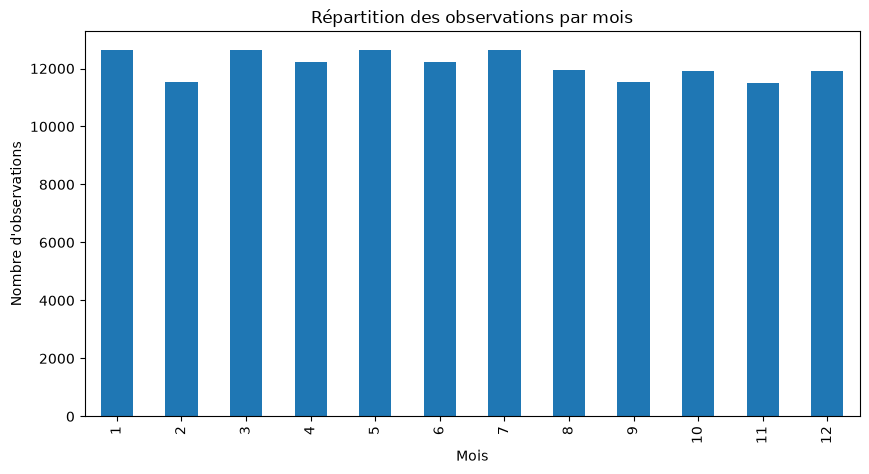

In [109]:
df["Month"].value_counts().sort_index().plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Répartition des observations par mois")
plt.xlabel("Mois")
plt.ylabel("Nombre d'observations")
plt.show()

In [110]:
df["Hour"].value_counts().sort_index()

Hour
0     6057
1     6058
2     6050
3     6041
4     6058
5     6058
6     6058
7     6058
8     6058
9     6058
10    6058
11    6058
12    6058
13    6058
14    6058
15    6058
16    6058
17    6058
18    6058
19    6058
20    6058
21    6058
22    6058
23    6058
Name: count, dtype: int64

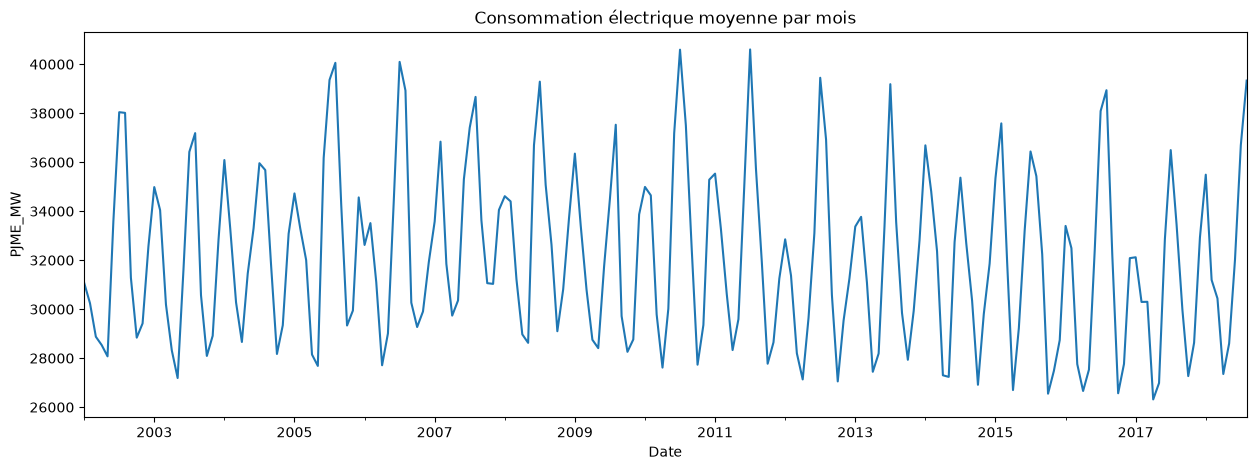

In [111]:
#time Serie Plot 
monthly = df.set_index("Datetime")["PJME_MW"].resample("ME").mean()  #resample() permet de regrouper les observations selon une fréquence temporelle.

monthly.plot(figsize=(15, 5))

plt.title("Consommation électrique moyenne par mois")
plt.xlabel("Date")
plt.ylabel("PJME_MW")
plt.show()

### Étape 2 : Nettoyage des données

In [112]:
print("duplicate values:", df.duplicated().sum())  #aucun valeur dupliquée
print("Value manquante:", df.isnull().sum())  #aucun valeur manquante

duplicate values: 0
Value manquante: Datetime    0
PJME_MW     0
Year        0
Month       0
Day         0
Hour        0
dtype: int64


In [113]:
print("duplicate dates:", df["Datetime"].duplicated().sum())  #date duplicate 

duplicates = df[df["Datetime"].duplicated(keep=False)]
duplicates.sort_values("Datetime")

duplicate dates: 4


,Datetime,PJME_MW,Year,Month,Day,Hour
106584,2014-11-02 02:00:00,22935.0,2014,11,2,2
106585,2014-11-02 02:00:00,23755.0,2014,11,2,2
115368,2015-11-01 02:00:00,21567.0,2015,11,1,2
115369,2015-11-01 02:00:00,21171.0,2015,11,1,2
124008,2016-11-06 02:00:00,20795.0,2016,11,6,2
124009,2016-11-06 02:00:00,21692.0,2016,11,6,2
132816,2017-11-05 02:00:00,21236.0,2017,11,5,2
132817,2017-11-05 02:00:00,20666.0,2017,11,5,2


In [114]:
#Remplace Duplicate observation par moyenne de la consommation électrique pour cette date
df = df.groupby("Datetime", as_index=False).agg({
    "PJME_MW": "mean"
})

In [115]:
#detection des outliers 
Q1 = df["PJME_MW"].quantile(0.25)
Q3 = df["PJME_MW"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df["PJME_MW"] < lower_bound) |(df["PJME_MW"] > upper_bound)]

print("Nombre d'outliers :", len(outliers))

Nombre d'outliers : 3455


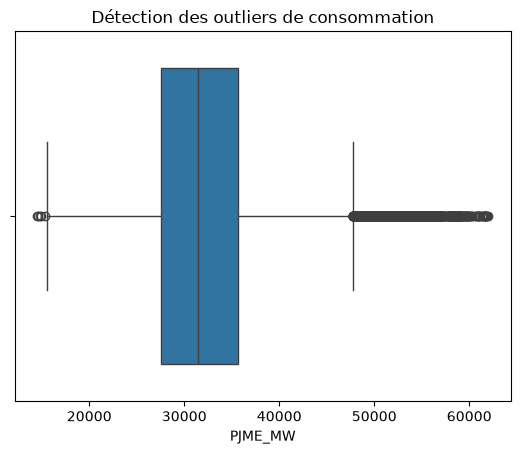

In [116]:
#Visualiser les outliers 
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(x=df["PJME_MW"])

plt.title("Détection des outliers de consommation")
plt.show()

In [117]:
#Vérifier si les dates sont triées par ordre croissant
df["Datetime"].is_monotonic_increasing

True

### Étape 4 : Feature Engineering